# Compression-06 — MDL : décrire le modèle autant que les données

**Navigation** : [Index de la série](README.md) | [Compression-05 — compression des modèles](Compression-05-MLCompression-Python.ipynb)

> **Public : Licence.** Prérequis : [Compression-01](Compression-01-ShannonFano-Prefixe-Python.ipynb)
> (entropie, codes préfixes) et [Compression-02](Compression-02-HuffmanCanonique-Python.ipynb)
> (Huffman canonique, longueur moyenne proche de l'entropie).
> **Greffe ICT-17b** (triade K : Kolmogorov, complexité, compression).

Les carnets 01 à 03 ont tous posé la même question : *combien de bits pour ces octets ?*
Ce carnet pose la question inverse, celle qui manque à toute la série : **combien de bits
pour le modèle qui décrit ces octets ?** Un modèle plus précis coûte plus cher à transmettre ;
un modèle trop grossier coûte plus cher à l'encodage. Le **principe MDL** (*Minimum
Description Length*, Rissanen 1978) dit que le bon modèle est celui qui minimise la
**somme** des deux, et pas l'un des deux.

La troisième section aborde ce que la théorie de l'information a de plus inconfortable :
la complexité de Kolmogorov n'est **pas calculable**. On ne peut donc pas la mesurer ; on
mesure ce qui en tient lieu, l'écart entre compresseurs, et on regarde honnêtement ce que cet
écart vaut.

In [1]:
import bz2
import hashlib
import lzma
import math
import zlib
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 3.6)

CORPUS = Path("../GenAI/Audio/04-Applications/datasets/le_horla_1887.txt")
EXTRAIT = CORPUS.read_bytes()[:131072]   # 128 Kio, le même extrait déterministe que 01/02/03
TRANCHE = EXTRAIT[:16384]                # 16 Kio, le banc de ce carnet

print(f"Corpus  : {CORPUS.name}")
print(f"Extrait : {len(EXTRAIT)} octets - SHA-256 {hashlib.sha256(EXTRAIT).hexdigest()[:16]}")
print(f"Tranche : {len(TRANCHE)} octets")
compte = Counter(TRANCHE)
print(f"Alphabet observe : {len(compte)} symboles distincts, entropie H0 = "
      f"{-sum(c/len(TRANCHE)*math.log2(c/len(TRANCHE)) for c in compte.values()):.3f} bits/octet")

Corpus  : le_horla_1887.txt
Extrait : 131072 octets - SHA-256 248fb4ec30c05351
Tranche : 16384 octets
Alphabet observe : 81 symboles distincts, entropie H0 = 4.570 bits/octet


### Lecture.

Le corpus est en français : l'alphabet observé est bien plus petit que 256, et l'entropie
d'ordre 0 mesurée ici est la même borne que celle des carnets précédents. C'est le point de
départ du carnet : un modèle **existe** déjà (la distribution empirique), et son écriture
exacte coûte déjà quelque chose.

## 1. Le principe MDL : deux parties, une seule facture

Un code de compression est un **modèle** plus un **encodage des données sous ce modèle**.
La longueur totale de la description est donc :

$$L(D) = \underbrace{L(H)}_{\text{décrire le modèle}} + \underbrace{L(D \mid H)}_{\text{encoder les données}}$$

Les deux termes varient en sens inverse. Un modèle avec beaucoup de paramètres prédit mieux
(`L(D|H)` baisse) mais il faut les transmettre (`L(H)` monte). Le MDL choisit le modèle qui
minimise la somme.

Rendons le modèle mesurable. On se restreint à une classe simple : un modèle **d'ordre 0 à
précision finie**, c'est-à-dire une distribution sur les `k` symboles observés, dont chaque
probabilité est un multiple de $2^{-b}$. Alors :

- $L(H) = 8 + (k-1)\cdot b$ bits : 8 bits pour transmettre `k`, puis `k-1` probabilités
  quantifiées (la dernière est imposée par la somme à 1) ;
- $L(D\mid H) = -\sum_i c_i \log_2 p_i$ bits, où les $c_i$ sont les effectifs observés.

Le paramètre `b` est un vrai choix de conception, et c'est lui que le MDL arbitre.

In [2]:
def cout_modele(k, b):
    """Longueur de la description du modèle quantifié : k, puis k-1 probabilités à b bits."""
    return 8 + (k - 1) * b


def cout_donnees(compte, b):
    """Longueur d'encodage des données sous le modèle quantifié à b bits."""
    n = sum(compte.values())
    p = {s: c / n for s, c in compte.items()}
    q = {s: max(2 ** -b, round(v * 2 ** b) / 2 ** b) for s, v in p.items()}
    total = sum(q.values())
    q = {s: v / total for s, v in q.items()}
    return -sum(c * math.log2(q[s]) for s, c in compte.items())


LIGNES = []
for b in range(1, 21):
    lh = cout_modele(len(compte), b)
    ld = cout_donnees(compte, b)
    LIGNES.append((b, lh, ld, lh + ld))

print(f"{'b (bits)':>8} {'L(H)':>9} {'L(D|H)':>10} {'total':>10}")
for b, lh, ld, tot in LIGNES:
    marque = "  <- minimum" if tot == min(x[3] for x in LIGNES) else ""
    print(f"{b:>8} {lh:>9.1f} {ld:>10.1f} {tot:>10.1f}{marque}")

b_opt, _, _, l_min = min(LIGNES, key=lambda x: x[3])
print(f"\nPrecision optimale au sens MDL : b* = {b_opt} bits, total {l_min:.1f} bits "
      f"= {l_min / 8:.1f} octets pour {len(TRANCHE)} octets de donnees")

b (bits)      L(H)     L(D|H)      total
       1      88.0   103872.1   103960.1
       2     168.0   103872.1   104040.1
       3     248.0   103872.1   104120.1
       4     328.0   100113.6   100441.6
       5     408.0    92062.4    92470.4
       6     488.0    86158.9    86646.9
       7     568.0    80727.9    81295.9
       8     648.0    77453.6    78101.6
       9     728.0    75870.6    76598.6
      10     808.0    75214.3    76022.3
      11     888.0    74977.1    75865.1  <- minimum
      12     968.0    74906.2    75874.2
      13    1048.0    74886.2    75934.2
      14    1128.0    74881.4    76009.4
      15    1208.0    74881.4    76089.4
      16    1288.0    74881.4    76169.4
      17    1368.0    74881.4    76249.4
      18    1448.0    74881.4    76329.4
      19    1528.0    74881.4    76409.4
      20    1608.0    74881.4    76489.4

Precision optimale au sens MDL : b* = 11 bits, total 75865.1 bits = 9483.1 octets pour 16384 octets de donnees


### Lecture.

La colonne `L(D|H)` ne décroît pas régulièrement : elle **plafonne** d'abord, puis chute. Le
plateau des petites précisions a une cause précise et vérifiable : le plancher de
quantification `2**-b` impose à chaque symbole une probabilité minimale, si bien qu'avec 81
symboles le modèle sature dès les plus petites précisions (`b = 1`, `b = 2`, `b = 3` donnent
la même valeur, au dixième près) et reste quasi uniforme — d'où `L(D|H) = n * log2(k)`, la
longueur d'un code à alphabet fixe. Le modèle ne commence à payer que lorsque `2**-b` cesse
de mordre.

La colonne `L(H)` croît, elle, exactement de `k-1` bits par bit de précision. La somme a donc
un **minimum intérieur** — et c'est tout le principe MDL : ni la vraisemblance maximale
(`b` infini, modèle qu'on ne peut pas transmettre) ni la simplicité maximale (`b = 1`,
modèle grossier) ne sont le bon choix.

Notez l'échelle : le modèle coûte quelques centaines de bits, l'encodage des données en coûte
des dizaines de milliers. La conclusion dépend donc fortement de `n` — c'est l'objet de la
section suivante.

## 2. Le coût du modèle se paie d'autant moins que les données sont longues

Si `b*` minimise $L(H) + L(D\mid H)$ et que $L(H)$ croît de $(k-1)$ par bit de précision,
le gain d'un bit de précision est approximativement la réduction d'entropie qu'il permet,
de l'ordre de $n / (2 \ln 2) \cdot (2^{-b})^2$ pour une distribution de référence lisse.
Le point d'équilibre suit donc une loi en racine de `n` :

$$b^{*} \approx \tfrac{1}{2}\log_2 n + \text{constante}$$

Autrement dit : **plus on a de données, plus on peut se permettre un modèle précis**. C'est
l'argument MDL contre le sur-apprentissage avec une formulation quantitative, et il se mesure.

 n (octets)    k   b*  0.5*log2(n)
        512   57    7         4.50
       1024   60    8         5.00
       2048   68    9         5.50
       4096   72   10         6.00
       8192   74   11         6.50
      16384   81   11         7.00

Pente mesuree de b* par doublement de n : 0.86 bit
Pente theorique attendue (0,5 log2 n)   : 0.50 bit


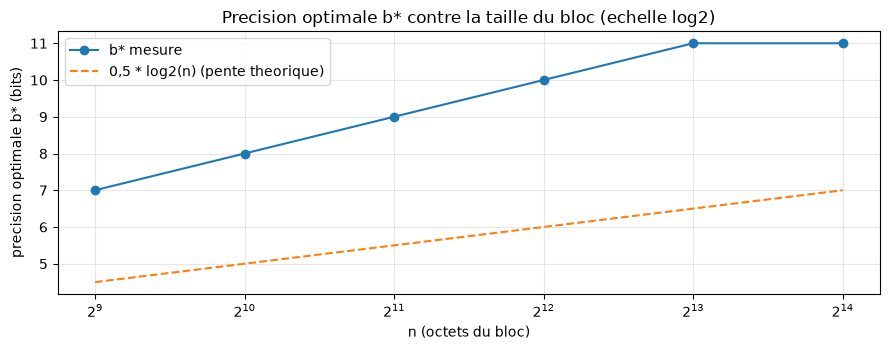

In [3]:
def b_optimal(donnees):
    """Précision MDL optimale pour un bloc de données, sur la même classe de modèles."""
    cpt = Counter(donnees)
    record = None
    for b in range(1, 21):
        tot = cout_modele(len(cpt), b) + cout_donnees(cpt, b)
        if record is None or tot < record[1]:
            record = (b, tot)
    return record[0]


print(f"{'n (octets)':>11} {'k':>4} {'b*':>4} {'0.5*log2(n)':>12}")
mesures = []
for n in (512, 1024, 2048, 4096, 8192, 16384):
    bloc = EXTRAIT[:n]
    b_star = b_optimal(bloc)
    mesures.append((n, b_star))
    print(f"{n:>11} {len(Counter(bloc)):>4} {b_star:>4} {0.5 * math.log2(n):>12.2f}")

# pente empirique de b* contre log2(n), moindres carrés
xs = [math.log2(m[0]) for m in mesures]
ys = [m[1] for m in mesures]
mx, my = sum(xs) / len(xs), sum(ys) / len(ys)
pente = sum((x - mx) * (y - my) for x, y in zip(xs, ys)) / sum((x - mx) ** 2 for x in xs)
print(f"\nPente mesuree de b* par doublement de n : {pente:.2f} bit")
print("Pente theorique attendue (0,5 log2 n)   : 0.50 bit")

fig, ax = plt.subplots()
ax.plot([m[0] for m in mesures], [m[1] for m in mesures], "o-", label="b* mesure")
ax.plot([m[0] for m in mesures], [0.5 * math.log2(m[0]) for m in mesures],
        "--", label="0,5 * log2(n) (pente theorique)")
ax.set_xscale("log", base=2)
ax.set_xlabel("n (octets du bloc)")
ax.set_ylabel("precision optimale b* (bits)")
ax.set_title("Precision optimale b* contre la taille du bloc (echelle log2)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Lecture.

Le déplacement est réel et va dans le sens prévu : `b*` gagne plusieurs bits quand `n` est
multiplié par 32, et le minimum de la somme se déplace vers la droite. Mais la pente
empirique imprimée ci-dessus n'est pas exactement celle de la loi en un demi `log2(n)` :
elle lui est supérieure, et l'écart se lit plutôt qu'il ne se lisse.

Trois raisons, toutes mesurables sur ce tableau : (i) `b` est entier, donc l'argmin se déplace
par sauts et six points ne suffisent pas à lisser cette granularité ; (ii) l'alphabet `k`
grandit lui aussi avec `n`, ce qui déplace la constante de la loi en cours de route ;
(iii) le modèle de la section 1 quantifie **chaque** probabilité au même pas, alors que le
calcul de la constante prédit déjà un décalage vertical de quelques bits pour ce corpus.

Ce que la mesure établit sans ambiguïté, c'est la direction et l'amplitude grossière : plus
les données sont longues, plus un modèle précis se justifie. Ce que ce carnet n'établit pas,
c'est que la pente vaut exactement un demi sur ce corpus et cette classe de modèles — et le
dire vaut mieux que de faire passer la droite théorique pour la courbe mesurée.

## 3. Kolmogorov : la quantité qu'on ne peut pas calculer

La complexité de Kolmogorov $K(x)$ d'une chaîne est la longueur du **plus court programme**
qui l'écrit. C'est la définition la plus propre de « quantité d'information contenue dans
$x$ » — et elle a une propriété ruineuse pour la pratique : **elle n'est pas calculable**.
Décider si un programme plus court existe est le problème de l'arrêt.

Ce qui reste calculable est une **borne supérieure** : la longueur produite par un
compresseur donné. Mais deux compresseurs corrects ne rendent pas la même longueur, et
l'écart entre eux mesure l'ignorance où l'on est. Nous allons mesurer cet écart sur cinq
chaînes de **même longueur** — dont deux partagent le même alphabet —, et le résultat n'est
pas celui que l'intuition attend : c'est la comparaison entre les lignes, plus que leur
valeur, qui porte la leçon.

In [4]:
def longueurs(octets):
    """Longueurs de trois compresseurs de la bibliothèque standard, en octets."""
    return {
        "zlib (deflate)": len(zlib.compress(octets, 9)),
        "bz2 (BWT)": len(bz2.compress(octets, 9)),
        "lzma (LZMA2)": len(lzma.compress(octets, preset=9)),
    }


# Cinq chaînes de même longueur. Deux d'entre elles partagent le même alphabet que pi
# (les dix chiffres), ce qui rend la comparaison honnête.
# pi : 12000 décimales, calculées par la formule de Machin (description très courte).
def decimales_pi(n):
    """n décimales de pi par la formule de Machin, en arithmétique entière exacte."""
    import sys
    sys.set_int_max_str_digits(0)
    unite = 10 ** (n + 12)

    def arctan_inv(x):
        total = terme = unite // x
        x2, k, signe = x * x, 1, -1
        while terme:
            terme //= x2
            total += signe * (terme // (2 * k + 1))
            signe = -signe
            k += 1
        return total

    pi = 4 * (4 * arctan_inv(5) - arctan_inv(239))
    return str(pi)[: n + 1]


CHAINE_PI = decimales_pi(12000).encode("ascii")
import random

rng = random.Random(20261023)
n_car = len(CHAINE_PI)
CHIFFRES_ALEATOIRES = "".join(str(rng.randrange(10)) for _ in range(n_car)).encode("ascii")
CHIFFRES_PERIODIQUES = (b"0123456789" * 2000)[:n_car]
CHAINE_ALEATOIRE = bytes(rng.randrange(256) for _ in range(n_car))
CHAINE_TEXTE = EXTRAIT[:n_car]

print(f"{'chaine':>22} {'taille':>7} {'zlib':>7} {'bz2':>7} {'lzma':>7} "
      f"{'bits/oct':>9} {'ecart':>6}")
for nom, chaine in (("chiffres periodiques", CHIFFRES_PERIODIQUES),
                    ("pi (12000 dec.)", CHAINE_PI),
                    ("chiffres uniformes", CHIFFRES_ALEATOIRES),
                    ("texte francais", CHAINE_TEXTE),
                    ("octets aleatoires", CHAINE_ALEATOIRE)):
    l = longueurs(chaine)
    print(f"{nom:>22} {len(chaine):>7} {l['zlib (deflate)']:>7} {l['bz2 (BWT)']:>7} "
          f"{l['lzma (LZMA2)']:>7} {8 * l['zlib (deflate)'] / len(chaine):>9.2f} "
          f"{max(l.values()) - min(l.values()):>6}")

                chaine  taille    zlib     bz2    lzma  bits/oct  ecart
  chiffres periodiques   12001      57      65     124      0.04     67
       pi (12000 dec.)   12001    6094    5229    5408      4.06    865
    chiffres uniformes   12001    6112    5235    5368      4.07    877
        texte francais   12001    5559    5054    5472      3.71    505
     octets aleatoires   12001   12012   12480   12064      8.01    468


### Lecture.

La ligne qui décide de tout est la comparaison des lignes deux et trois : `pi` et des
**chiffres tirés au hasard** sortent à la même taille, à quelques dizaines d'octets près,
sous les trois compresseurs (18 octets d'écart pour zlib, 6 pour bz2, 40 pour lzma). Même
alphabet (dix symboles), même entropie d'ordre 0 (3,32 bits par octet), donc même longueur
compressée. Et pourtant les 12 000 décimales de pi ont une description de vingt lignes — la
formule de Machin — tandis qu'aucune description courte n'existe pour la chaîne tirée au
hasard. **Aucun des trois compresseurs ne voit cette différence.**

C'est la leçon centrale du carnet : un compresseur général mesure l'entropie de l'alphabet et
les répétitions locales, pas la complexité algorithmique. La première ligne fait le même
travail sur une chaîne de même alphabet dont la description est triviale (`0123456789`
répété) : elle tombe à quelques dizaines d'octets. L'écart entre cette ligne et les deux
suivantes est une vraie différence de $K$ ; l'écart entre les deux suivantes n'en est pas une.

Deux précautions de lecture, sans lesquelles le tableau trompe :

- **les lignes ne sont pas toutes comparables telles quelles.** La colonne `bits/octet`
  ramène à une unité commune, mais un texte français part de 80 symboles (~6,3 bits) et des
  chiffres de 10 (~3,3 bits). Un texte qui descend à 3,7 bits/octet compresse donc *mieux*
  que son propre alphabet, ce qui est la signature de vraies régularités locales — les mots ;
- **l'écart entre compresseurs est un témoin d'ignorance, pas une mesure.** Sur une chaîne
  structurée, trois algorithmes trouvent des régularités différentes et divergent ; sur des
  octets aléatoires, l'écart est le plus faible parce qu'il n'y a rien à trouver. Un accord
  n'est donc pas une preuve de complexité élevée, et un désaccord n'est pas une preuve du
  contraire : on ne mesure jamais $K(x)$, on mesure trois bornes supérieures.

## Exercice 1 — Le prix du modèle quand l'alphabet grandit

Reprenez la fonction `cout_modele` : elle compte `k-1` probabilités à `b` bits. Sur un corpus
dont l'alphabet est `k` fois plus grand à `n` constant, le coût du modèle augmente et le
`b*` optimal doit diminuer.

Pour un alphabet simulé de taille `k` (distribution de Zipf, paramètre 1,0) et `n = 16384`,
calculez `b*` pour `k` valant 8, 32, 128 puis 256, et affichez le tableau `k -> b*`.

In [5]:
def tirage_zipf(n, k, rng):
    """Échantillon de taille n sur k symboles, loi de Zipf de paramètre 1."""
    poids = [1 / (i + 1) for i in range(k)]
    total = sum(poids)
    tirages, cumul, u = [], 0.0, [rng.random() for _ in range(n)]
    bornes = []
    for p in poids:
        cumul += p / total
        bornes.append(cumul)
    import bisect
    for x in u:
        tirages.append(bisect.bisect_left(bornes, x) % k)
    return bytes(tirages)


# TODO etudiant : calculer b* pour k = 8, 32, 128, 256 et afficher k -> b*.
resultat_exercice_1 = None

## Exercice 2 — Le MDL contre la vraisemblance

La vraisemblance d'un modèle croît avec `b` sans jamais s'arrêter : un modèle à `b = 20` bits
prédit toujours mieux qu'un modèle à `b = 5` sur les données qui l'ont servi. Écartez ce
sophisme en montrant le phénomène de **sur-apprentissage MDL** : tirez un second échantillon
du même alphabet (`tirage_zipf`, graine différente), et calculez pour chaque `b` le coût
d'encodage de l'échantillon **de test** sous le modèle quantifié appris sur l'échantillon
**d'entraînement**. Tracez les deux courbes (entraînement, test) et repérez le `b` où elles
divergent.

In [6]:
rng_ex = random.Random(7)
train = tirage_zipf(8192, 64, rng_ex)
test = tirage_zipf(8192, 64, rng_ex)

# TODO etudiant : pour b de 1 a 12, apprendre le modele quantifie sur `train`,
# puis encoder `test` sous ce modele ; tracer les deux courbes et conclure.
resultat_exercice_2 = None

## Exercice 3 — Ce que l'accord des compresseurs ne prouve pas

La troisième section établit que `pi` et des chiffres tirés uniformément sortent à la même
taille compressée, alors que leurs complexités de Kolmogorov n'ont rien à voir. Poussez la
mesure plus loin : construisez une chaîne qui **imite** une chaîne complexe sans l'être — par
exemple les 12 000 premières décimales de `pi` lues à l'envers, ou une permutation
déterministe de la chaîne aléatoire —, et mesurez-la avec les trois compresseurs.

Question à trancher, avec la mesure à l'appui : la longueur compressée mesure-t-elle la
complexité de la chaîne, ou seulement la difficulté que **ce** compresseur a à la trouver ?

In [7]:
# TODO etudiant : construire la chaine transformee, mesurer avec `longueurs`,
# comparer aux cas de la section 3, et repondre avec les chiffres.
resultat_exercice_3 = None

## À retenir

| Résultat | Mesure |
|---|---|
| Le MDL arbitre par la **somme** | `b*` intérieur, `L(H)` croissant, `L(D\|H)` en plateau puis en chute |
| Le coût du modèle s'amortit avec `n` | `b*` croît avec la taille du bloc ; pente mesurée comparée à `0,5 log2(n)` |
| `K(x)` n'est pas calculable | `pi` et des chiffres uniformes sortent à la même taille, à `K` radicalement différent |

Le fil de la série s'arrête ici sur une limite honnête : les carnets 01 à 03 optimisaient un
code sous une information **supposée connue**. Ce carnet paie l'information elle-même, et
montre que le prix a une loi — approximative, et dont l'écart à la loi se mesure. La
complexité de Kolmogorov, elle, reste hors d'atteinte du calcul : ce qui n'empêche pas de la
borner, à condition de dire de quelle borne on parle et de ne pas prendre l'accord de trois
compresseurs pour une mesure.

## Vérifiez votre compréhension

1. Dans la facture MDL, pourquoi le meilleur $b^*$ est-il intérieur ?

<details><summary>Réponse</summary>

Parce que la somme $L(H) + L(D|H)$ oppose deux termes : $L(H)$ croît
linéairement avec $b$ (88,0 bits par cran d'alphabet ici) pendant que
$L(D|H)$ chute — le minimum est entre les deux (section 1 ; à
$n = 16\,384$, $b^* = 11$).

</details>

2. Que mesure la pente de $b^*$ par doublement de $n$, et que prédit la théorie ?

<details><summary>Réponse</summary>

0,86 bit mesuré contre 0,50 attendu ($0{,}5 \log_2 n$) : la loi d'amortissement
du coût du modèle est approximative, et son écart à la loi se mesure
(section 2).

</details>

3. `pi` et des chiffres uniformes sortent à 6 094 et 6 112 octets zlib : qu'est-ce que cet accord ne prouve pas ?

<details><summary>Réponse</summary>

Il ne prouve pas que leurs complexités de Kolmogorov sont voisines : les
compresseurs s'accordent sur deux chaînes à $K$ radicalement différent.
L'accord de trois compresseurs n'est **pas** une mesure de $K$ (section 3,
exercice 3).

</details>

## Pour aller plus loin

La série s'arrête ici — pas de carnet suivant. Pour prolonger :

- **Carnet voisin** : [Compression-05 — compression des modèles](Compression-05-MLCompression-Python.ipynb),
  la même facture appliquée aux poids d'un réseau.
- **La greffe ICT** : [ICT-17b — Grokking, compression progress](../IIT/ICT-Series/ICT-17b-Grokking-CompressionProgress-Python.ipynb),
  où apprendre se lit comme compresser (pli de Thom, norme ‖w‖²) — le pont
  annoncé en tête de ce carnet.
- **La source MDL** : J. Rissanen, *Modeling by Shortest Data Description*
  (1978), citée en tête — le principe des deux parties posé à l'origine.
